# Neural net experiments

**Goal:** see whether a small neural network (scikit-learn's `MLPClassifier`) finds class signal
that carries over to new subjects.

**Background from `ada_boost.ipynb`:** AdaBoost barely ranks unseen subjects (grouped AUC about
0.55). The features seem to identify *who* a row came
from more than *what class* it is.

**Why a neural net:** unlike trees, a neural net needs scaled inputs, so we have to choose how to
scale. That makes this a natural place to test the main idea from the AdaBoost notebook: **scaling
each feature within its own subject** to remove each subject's "signature".

The submission is in section 12 (hybrid, probabilities).

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

> **Metric correction (2026-10-15).** The leaderboard scores **ROC AUC on submitted
> probabilities**, not accuracy. The leaderboard showed it: an all-1s file scored exactly 0.50000,
> which is what AUC gives any constant prediction, and our 0/1-label hybrid scored only 0.586,
> although its known-subject AUC is about 0.89. Submitting the same model's *probabilities* scored
> **0.70**. This notebook has been re-run with AUC as the metric. Models are chosen by AUC,
> submissions contain P(class 1), and threshold tuning has been removed, because AUC does not depend
> on a threshold. Some tables still show accuracy for reference.

In [1]:
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=UserWarning)  # sklearn feature-name warnings

RANDOM_STATE = 42

## 1. Load and preprocess (same steps as `ada_boost.ipynb` section 3)

In [2]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")

target = "output"
groups = train["subject"]

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    X = pd.get_dummies(X, columns=["state"], dtype=int)
    return X

X_full = prep(train)
X_test = prep(test).reindex(columns=X_full.columns, fill_value=0)
y = train[target]

const_cols = X_full.columns[X_full.nunique() <= 1]
X_full = X_full.drop(columns=const_cols)
X_test = X_test.drop(columns=const_cols)
print(f"Dropped {len(const_cols)} constant columns -> {X_full.shape[1]} features")

Dropped 108 constant columns -> 564 features


## 2. Evaluation harness

The same harness as the AdaBoost notebook, scored mainly by **ROC AUC**, the competition metric. AUC
measures whether the model *ranks* class-0 rows below class-1 rows, whatever the threshold. 0.5 is
random (or a constant prediction) and 1.0 is a perfect ranking. Accuracy and macro-F1 are kept for
reference.

**Leaderboard proxy.** 54% of test rows come from unseen subjects (E, J). Our submissions give
those rows a constant score, the training class-1 rate (0.845), because no model has ranked unseen
subjects better than that (see `automl.ipynb` §7). To estimate the leaderboard AUC from training data
alone, `lb_proxy` picks 300 random groups of training subjects that together cover 45–60% of rows. It
gives their rows the constant, gives every other row the model's out-of-fold probability, and
averages the pooled AUC. Against real submissions, the proxy gave **0.753** for the submission that
scored **0.70**, and **0.720** for one that scored **0.68**. So it reads about 0.04–0.05 high, but it
puts submissions in the right order.

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
results = []

def evaluate(name, model, X=None):
    X = X_full if X is None else X
    row = {"model": name}
    for cv_name, cv, kw in [("strat", skf, {}), ("group", gkf, {"groups": groups})]:
        s = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                           scoring=["accuracy", "f1_macro", "roc_auc"], **kw)
        row[f"{cv_name}_acc"] = s["test_accuracy"].mean()
        row[f"{cv_name}_f1m"] = s["test_f1_macro"].mean()
        row[f"{cv_name}_auc"] = s["test_roc_auc"].mean()
    results.append(row)
    return pd.Series(row)

PRIOR = (y == 1).mean()
g_arr = np.asarray(groups, dtype=object)
_sizes = pd.Series(g_arr).value_counts()
_all = [c for r in range(3, 8) for c in itertools.combinations(sorted(_sizes.index), r)
        if 0.45 <= _sizes[list(c)].sum() / len(g_arr) <= 0.60]
_rng = np.random.default_rng(RANDOM_STATE)
proxy_subsets = [_all[i] for i in _rng.choice(len(_all), 300, replace=False)]

def lb_proxy(p_known, p_unseen=None):
    """Mean pooled AUC when ~54% of rows (random subject groups) get p_unseen (default: the
    constant PRIOR, as E/J do in our submissions) and the rest get out-of-fold p_known."""
    p_unseen = np.full(len(y), PRIOR) if p_unseen is None else np.asarray(p_unseen)
    return np.mean([roc_auc_score(y, np.where(np.isin(g_arr, s), p_unseen, p_known))
                    for s in proxy_subsets])

def within_subject_auc(p):
    """AUC inside each subject that has both classes."""
    return pd.Series({s: roc_auc_score(y[g_arr == s], p[g_arr == s])
                      for s in np.unique(g_arr) if y[g_arr == s].nunique() > 1})

evaluate("majority baseline", DummyClassifier(strategy="most_frequent"))

model        majority baseline
strat_acc             0.844895
strat_f1m             0.457964
strat_auc                  0.5
group_acc             0.852051
group_f1m              0.45784
group_auc                  0.5
dtype: object

## 3. Experiment 1: MLP with ordinary (global) scaling

**Hypothesis:** a neural net with standard scaling (mean 0, std 1 for each feature, computed over all
training rows) will act like AdaBoost. It will do fine on subjects it has seen and fall back to
predicting all 1s on new subjects, because global scaling leaves each subject's signature in place.

The scaler sits inside a pipeline, so in each CV fold it's fitted on the training folds only.

In [4]:
def mlp(hidden=(64,), alpha=1e-3):
    return MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, early_stopping=True,
                         max_iter=500, random_state=RANDOM_STATE)

evaluate("MLP (64), global scaling", make_pipeline(StandardScaler(), mlp()))

model        MLP (64), global scaling
strat_acc                    0.845113
strat_f1m                    0.527959
strat_auc                    0.659518
group_acc                    0.837382
group_f1m                    0.465531
group_auc                     0.54741
dtype: object

**Interpretation:** this hypothesis was mostly right. On subjects it has seen, the MLP has real
ranking signal (shuffled AUC 0.66), but on new subjects that drops to 0.55, barely above random.
Grouped accuracy (0.837) is *below* the baseline (0.852). Unlike AdaBoost it does predict some 0s,
but mostly wrongly.

## 4. Experiment 2: MLP with per-subject scaling

**Hypothesis:** if each subject has its own offset and spread (a "signature"), z-scoring every
feature **within each subject** removes it. The model then sees "how unusual is this row *for this
subject*", which should carry over to new subjects. Grouped AUC should go up.

**Is this allowed?** Yes. The scaling uses only the feature values of a subject's own rows, never
their labels. For the test set, E and J can be scaled with their own test rows, which needs no
labels either. In grouped CV, the held-out subjects are scaled the same way, so this mirrors the
test situation.

We only scale the continuous sensor features. `phase` and the `state_*` columns are left as they
are, because they describe conditions, not measurements.

In [5]:
cond_cols = ["phase"] + [c for c in X_full.columns if c.startswith("state_")]
sensor_cols = [c for c in X_full.columns if c not in cond_cols]

def per_subject_scale(X, subj):
    X = X.copy()
    g = X[sensor_cols].groupby(subj.values)
    mean = g.transform("mean")
    std = g.transform("std").replace(0, np.nan)
    # A feature that is constant within one subject becomes 0 for that subject
    X[sensor_cols] = ((X[sensor_cols] - mean) / std).fillna(0)
    return X

X_subj = per_subject_scale(X_full, groups)
X_test_subj = per_subject_scale(X_test, test["subject"])  # ready for a later submission

# A final global scaler keeps the condition columns on a similar scale to the rest
evaluate("MLP (64), per-subject scaling", make_pipeline(StandardScaler(), mlp()), X_subj)

model        MLP (64), per-subject scaling
strat_acc                         0.835079
strat_f1m                         0.488764
strat_auc                          0.60982
group_acc                         0.812648
group_f1m                         0.460281
group_auc                         0.490663
dtype: object

**Interpretation:** this hypothesis was wrong. Per-subject scaling made things **worse**: grouped
AUC fell to 0.49 (random) and grouped accuracy to 0.813. So either the class signal isn't a
within-subject change, or scaling within a subject also removed the useful part. One possible
reason: some subjects are almost all one class (K is 100% class 1). For them, "unusual for this
subject" can't mean "class 0".

## 5. Experiment 3: network size and regularisation

**Hypothesis:** with only 11 training subjects, a bigger network will memorise subject-specific
patterns. Stronger L2 regularisation (`alpha`) and smaller layers should carry over better to new
subjects.

This uses whichever scaling did better on grouped AUC in experiments 1 and 2.

In [6]:
res = pd.DataFrame(results).set_index("model")
use_subj = res.loc["MLP (64), per-subject scaling", "group_auc"] > res.loc["MLP (64), global scaling", "group_auc"]
X_best = X_subj if use_subj else X_full
scaling = "per-subject" if use_subj else "global"
print("Using", scaling, "scaling")

grid = []
for hidden in [(16,), (64,), (128, 64)]:
    for alpha in [1e-4, 1e-2, 1.0]:
        s = evaluate(f"MLP {hidden}, alpha={alpha}, {scaling}",
                     make_pipeline(StandardScaler(), mlp(hidden, alpha)), X_best)
        grid.append({"hidden": str(hidden), "alpha": alpha,
                     "group_acc": s.group_acc, "group_auc": s.group_auc})

grid = pd.DataFrame(grid)
grid.pivot(index="hidden", columns="alpha", values="group_auc").round(3)

Using global scaling


alpha,0.0001,0.0100,1.0000
hidden,,,
"(128, 64)",0.590,0.544,0.568
"(16,)",0.517,0.516,0.526
"(64,)",0.551,0.550,0.560


**Interpretation:** all settings are close, with grouped AUC between 0.52 and 0.59. The largest
network with the weakest regularisation, (128, 64) with alpha=0.0001, scores best at 0.59. That's
the opposite of the hypothesis, but the gap is small for a single random seed, so it may be noise.
No setting beats the baseline on grouped accuracy.

## 6. Results so far

In [7]:
pd.DataFrame(results).set_index("model").round(4)

,strat_acc,strat_f1m,strat_auc,group_acc,group_f1m,group_auc
model,,,,,,
majority baseline,0.8449,0.4580,0.5000,0.8521,0.4578,0.5000
"MLP (64), global scaling",0.8451,0.5280,0.6595,0.8374,0.4655,0.5474
"MLP (64), per-subject scaling",0.8351,0.4888,0.6098,0.8126,0.4603,0.4907
"MLP (16,), alpha=0.0001, global",0.8442,0.5391,0.6679,0.8355,0.4665,0.5165
"MLP (16,), alpha=0.01, global",0.8423,0.5415,0.6710,0.8321,0.4614,0.5161
"MLP (16,), alpha=1.0, global",0.8445,0.5403,0.6774,0.8376,0.4608,0.5259
"MLP (64,), alpha=0.0001, global",0.8445,0.5291,0.6606,0.8370,0.4625,0.5506
"MLP (64,), alpha=0.01, global",0.8442,0.5290,0.6606,0.8376,0.4656,0.5505
"MLP (64,), alpha=1.0, global",0.8453,0.5433,0.6833,0.8385,0.4664,0.5605


## 7. Experiment 4: pooled vs within-subject ranking on held-out subjects

**Hypothesis:** the leaderboard computes one pooled AUC over all test rows, so a model needs the
right *order* inside each subject and the right *level* across subjects. On unseen subjects the net
may rank rows a little inside each subject but get the levels wrong, so its pooled AUC will be lower
than its within-subject AUC.

We get one out-of-fold probability per training row with grouped CV, so each row is scored by a
model that never saw its subject.

In [8]:
best_row = grid.loc[grid.group_auc.idxmax()]
best_model = make_pipeline(StandardScaler(), mlp(eval(best_row.hidden), best_row.alpha))
print(f"Best: hidden={best_row.hidden}, alpha={best_row.alpha}, scaling={scaling}")

proba_1 = cross_val_predict(best_model, X_best, y, cv=gkf, groups=groups,
                            method="predict_proba", n_jobs=-1)[:, 1]
within = within_subject_auc(proba_1)
print(f"Pooled out-of-fold grouped AUC: {roc_auc_score(y, proba_1):.3f}")
print(f"Mean within-subject AUC:        {within.mean():.3f}")
within.round(3).rename("within-subject AUC (subject unseen)").to_frame().T

Best: hidden=(128, 64), alpha=0.0001, scaling=global


Pooled out-of-fold grouped AUC: 0.515
Mean within-subject AUC:        0.560


,A,B,C,D,F,G,H,I,L,M
within-subject AUC (subject unseen),0.763,0.61,0.534,0.566,0.595,0.504,0.406,0.454,0.732,0.438


**Interpretation:** the hypothesis held. The best `MLPClassifier`, (128, 64) with α = 0.0001, has a
pooled out-of-fold grouped AUC of **0.515**, below its mean within-subject AUC of **0.560**. The
within-subject ranking is uneven: A 0.76 and L 0.73, but H, I and M are below 0.5. The net ranks
rows inside some new subjects and puts their levels in the wrong place.

## 8. Feature importance (permutation, held-out subjects)

**Hypothesis:** if per-subject scaling helped, the important features should now be ones that change
*within* a subject between class 0 and class 1, rather than ones that tell subjects apart.

Held-out subjects: ['C', 'I']


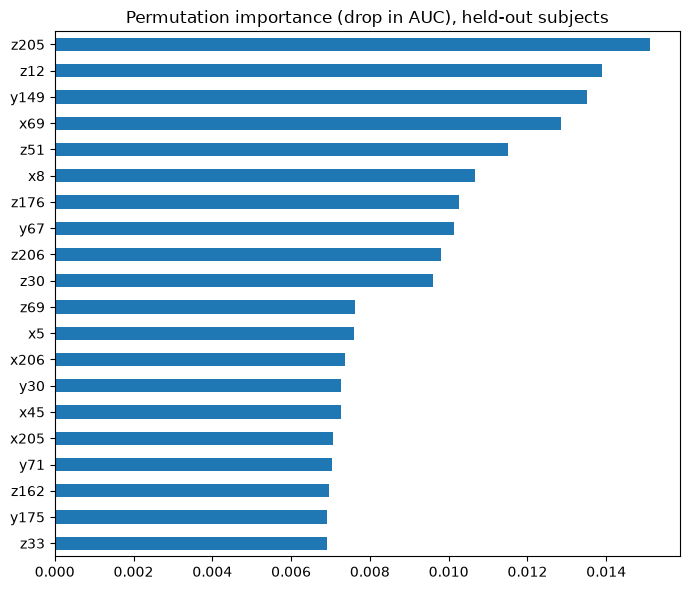

In [9]:
tr_idx, va_idx = next(GroupKFold(n_splits=4).split(X_best, y, groups))
best_model.fit(X_best.iloc[tr_idx], y.iloc[tr_idx])
print("Held-out subjects:", sorted(groups.iloc[va_idx].unique()))

perm = permutation_importance(best_model, X_best.iloc[va_idx], y.iloc[va_idx],
                              scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_best.columns).sort_values(ascending=False)
perm_imp.head(20)[::-1].plot.barh(figsize=(7, 6),
                                  title="Permutation importance (drop in AUC), held-out subjects")
plt.tight_layout()

**Interpretation:** the top features are `z205`, `z12`, `y149`, `x69` and `z51`. Each drops AUC by
only about 0.01–0.015 when shuffled, and about 30 features pass 0.005. So the signal is weak and
spread across all three blocks, with no single dominant feature. There's no overlap with AdaBoost's
top features (`phase`, `x50`, `z207`...), which supports the idea that neither model has found a
stable signal.

We use AUC instead of accuracy for importance. A model that predicts all 1s has an accuracy that
never changes when a feature is shuffled, which is why every feature showed about 0 importance in
the AdaBoost notebook.

## 9. Experiment 5: dropout, stronger L2, and subject-aware early stopping (PyTorch)

**Are we using GroupKFold?** Yes. Every `group_*` score above comes from `GroupKFold(n_splits=5)` by
subject. One step didn't respect subjects, though: `MLPClassifier(early_stopping=True)` holds out a
*random* 10% of training rows to decide when to stop. Those rows come from subjects the net is already
training on, so it stops at the point that best fits *known* subjects, which encourages memorising them.

This section rebuilds the MLP in PyTorch so we can change three things:
- **Dropout** after every hidden layer. `MLPClassifier` has no dropout.
- **Decoupled weight decay** (AdamW) instead of the L2 penalty `alpha`. With Adam, an L2 penalty is
  weaker on weights that get large gradients. AdamW shrinks every weight at the same rate, which
  regularises more cleanly. We go up to 1.0.
- **Early stopping on held-out subjects**: inside each GroupKFold training fold, about 20% of the
  training *subjects* form the early-stopping set.

**Hypothesis:** the (128, 64) net from section 5 has the best grouped AUC (0.59) but also the
largest gap from shuffled CV, so it is memorising subjects. Dropout and stronger weight decay should
reduce that and raise grouped AUC. Subject-aware early stopping should stop training before the net
starts fitting subject-specific patterns.

Each setting is averaged over **3 seeds**, because single-seed differences in section 5 were within
noise. Same folds, same global scaling (fitted in each fold), same features as section 5.

In [10]:
import torch
from torch import nn
from joblib import Parallel, delayed
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit

def make_net(n_in, hidden, dropout):
    layers, d = [], n_in
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
        d = h
    layers.append(nn.Linear(d, 1))
    return nn.Sequential(*layers)

def fit_predict(X_tr, y_tr, g_tr, X_va, hidden, dropout, weight_decay, seed,
                es="subject", lr=1e-3, batch=128, max_epochs=200, patience=20, return_epoch=False):
    """Train one net and return P(class 1) for X_va.

    es="subject": early stopping holds out ~20% of the training *subjects*, so training stops
    when the net stops improving on people it hasn't seen. es="row" holds out random rows
    instead, like MLPClassifier(early_stopping=True).
    """
    torch.set_num_threads(1)  # many small nets run in parallel, one core each
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(X_tr)
    X_tr, X_va = scaler.transform(X_tr), scaler.transform(X_va)
    splitter = GroupShuffleSplit if es == "subject" else ShuffleSplit
    fit_idx, es_idx = next(splitter(n_splits=1, test_size=0.2, random_state=seed)
                           .split(X_tr, y_tr, g_tr if es == "subject" else None))
    t = lambda a: torch.tensor(a, dtype=torch.float32)
    Xf, yf, Xe, ye = t(X_tr[fit_idx]), t(y_tr[fit_idx]), t(X_tr[es_idx]), t(y_tr[es_idx])

    net = make_net(X_tr.shape[1], hidden, dropout)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    gen = torch.Generator().manual_seed(seed)
    best_loss, best_state, bad, best_epoch = np.inf, None, 0, 0
    for epoch in range(max_epochs):
        net.train()
        for idx in torch.randperm(len(Xf), generator=gen).split(batch):
            opt.zero_grad()
            loss_fn(net(Xf[idx]).squeeze(1), yf[idx]).backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            es_loss = loss_fn(net(Xe).squeeze(1), ye).item()
        if es_loss < best_loss - 1e-4:
            best_loss, bad, best_epoch = es_loss, 0, epoch + 1
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state)
    with torch.no_grad():
        proba = torch.sigmoid(net(t(X_va)).squeeze(1)).numpy()
    return (proba, best_epoch) if return_epoch else proba

In [11]:
Xv = X_full.values.astype(np.float32)
yv = y.values.astype(np.float32)
gv = groups.values
folds = list(gkf.split(Xv, yv, gv))
SEEDS = [0, 1, 2]

def grouped_oof(configs):
    """Out-of-fold P(class 1) for every config and seed, using the same GroupKFold folds as above."""
    tasks = [(ci, s, k) for ci in range(len(configs)) for s in SEEDS for k in range(len(folds))]
    preds = Parallel(n_jobs=-1)(
        delayed(fit_predict)(Xv[folds[k][0]], yv[folds[k][0]], gv[folds[k][0]], Xv[folds[k][1]],
                             seed=s, **configs[ci])
        for ci, s, k in tasks)
    oof = np.zeros((len(configs), len(SEEDS), len(yv)))
    for (ci, s, k), p in zip(tasks, preds):
        oof[ci, s, folds[k][1]] = p
    return oof

def fold_scores(p):
    """Mean over folds, like cross_validate, so numbers are comparable with the table above."""
    acc, f1, auc = [], [], []
    for _, va in folds:
        pred = (p[va] >= 0.5).astype(int)
        acc.append(accuracy_score(y.iloc[va], pred))
        f1.append(f1_score(y.iloc[va], pred, average="macro"))
        auc.append(roc_auc_score(y.iloc[va], p[va]))
    return np.mean(acc), np.mean(f1), np.mean(auc)

configs = [dict(hidden=(128, 64), dropout=d, weight_decay=w)
           for d in [0.0, 0.2, 0.4, 0.6] for w in [1e-4, 1e-2, 1e-1, 1.0]]
oof = grouped_oof(configs)

rows = []
for c, o in zip(configs, oof):
    s = np.array([fold_scores(p) for p in o])  # one row per seed
    rows.append({"dropout": c["dropout"], "weight_decay": c["weight_decay"],
                 "group_acc": s[:, 0].mean(), "group_f1m": s[:, 1].mean(),
                 "group_auc": s[:, 2].mean(), "group_auc_seed_std": s[:, 2].std()})
torch_grid = pd.DataFrame(rows)
torch_grid.pivot(index="dropout", columns="weight_decay", values="group_auc").round(3)

weight_decay,0.0001,0.0100,0.1000,1.0000
dropout,,,,
0.0,0.513,0.513,0.512,0.507
0.2,0.508,0.504,0.502,0.505
0.4,0.505,0.505,0.504,0.503
0.6,0.488,0.483,0.486,0.496


,dropout,weight_decay,group_acc,group_f1m,group_auc,group_auc_seed_std
1,0.0,0.0100,0.8520,0.4626,0.5129,0.0088
0,0.0,0.0001,0.8520,0.4626,0.5126,0.0090
2,0.0,0.1000,0.8520,0.4626,0.5124,0.0090
4,0.2,0.0001,0.8521,0.4578,0.5084,0.0131
3,0.0,1.0000,0.8456,0.4561,0.5074,0.0027
7,0.2,1.0000,0.8469,0.4565,0.5053,0.0093


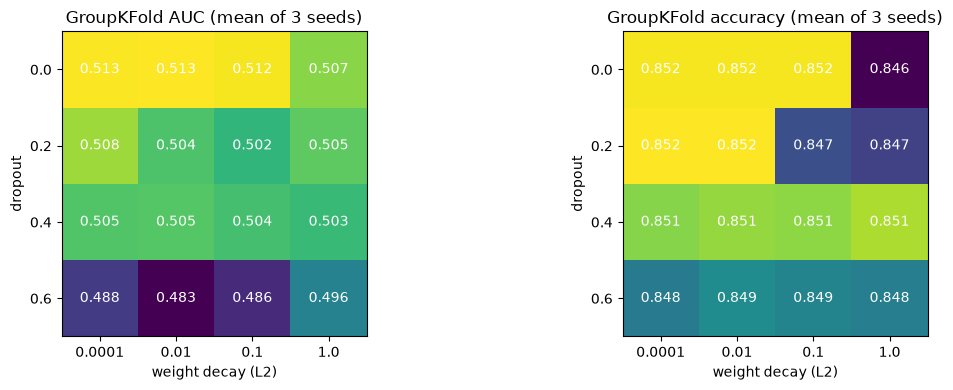

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "group_auc", "GroupKFold AUC"), (axes[1], "group_acc", "GroupKFold accuracy")]:
    piv = torch_grid.pivot(index="dropout", columns="weight_decay", values=col)
    im = ax.imshow(piv.values, cmap="viridis")
    ax.set_xticks(range(piv.shape[1]), piv.columns)
    ax.set_yticks(range(piv.shape[0]), piv.index)
    ax.set_xlabel("weight decay (L2)")
    ax.set_ylabel("dropout")
    ax.set_title(title + " (mean of 3 seeds)")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", color="w")
plt.tight_layout()
torch_grid.sort_values("group_auc", ascending=False).round(4).head(6)

**Interpretation:** this hypothesis was wrong. Every setting scores a grouped AUC of **0.48–0.51**,
which is random and *below* the 0.55–0.59 from `MLPClassifier` in section 5. More dropout makes it
slightly worse (0.6 is the worst row). Weight decay barely matters: each row of the table changes by
≤0.01, which is about the seed std. Grouped accuracy is about 0.852 because the nets predict all 1s.
Section 9b shows why.

### 9b. Which change caused that? Early-stopping split vs dropout/weight decay

Section 9 changed two things at once. Here we cross the early-stopping split (held-out **subjects**
vs random **rows**) with dropout and weight decay, and record the epoch early stopping chose.

In [13]:
abl_cfgs = [dict(es=es, dropout=d, weight_decay=w)
            for es in ["subject", "row"] for d in [0.0, 0.4] for w in [1e-4, 1e-1]]
abl_tasks = [(ci, s, k) for ci in range(len(abl_cfgs)) for s in SEEDS for k in range(len(folds))]
abl_out = Parallel(n_jobs=-1)(
    delayed(fit_predict)(Xv[folds[k][0]], yv[folds[k][0]], gv[folds[k][0]], Xv[folds[k][1]],
                         hidden=(128, 64), seed=s, return_epoch=True, **abl_cfgs[ci])
    for ci, s, k in abl_tasks)
abl = pd.DataFrame([{**abl_cfgs[ci], "group_auc": roc_auc_score(y.iloc[folds[k][1]], p), "best_epoch": e}
                    for (ci, s, k), (p, e) in zip(abl_tasks, abl_out)])
abl.groupby(["es", "dropout", "weight_decay"]).agg(
    group_auc=("group_auc", "mean"), median_epoch=("best_epoch", "median"),
    max_epoch=("best_epoch", "max")).round(3)

group_auc  median_epoch  max_epoch
es      dropout weight_decay                                    
row     0.0     0.0001            0.546           4.0          5
                0.1000            0.550           4.0          5
        0.4     0.0001            0.542           5.0          7
                0.1000            0.546           5.0          7
subject 0.0     0.0001            0.513           2.0          2
                0.1000            0.512           2.0          2
        0.4     0.0001            0.505           2.0          5
                0.1000            0.504           2.0          5

**Interpretation:** the drop comes from the **early-stopping split**, not from dropout or weight
decay:
- With **held-out subjects** for early stopping, the loss on unseen people is lowest after **2 epochs**
  (median). After that, more training only makes predictions on new subjects worse, so the net
  barely trains and its AUC is about 0.51.
- With **random rows** (as `MLPClassifier` does), training runs a little longer (epoch 4–5) and
  grouped AUC is about 0.55, matching section 5. Those extra epochs pick up the weak signal that
  section 5 measured.
- Dropout and weight decay change AUC by ≤0.008 under either split, which is noise.

This is the clearest evidence so far for what the AdaBoost and random forest notebooks suggested: the
signal that transfers between subjects is tiny, and it's learned in the first few epochs. **The
network isn't overfitting because it's too big**, which is the problem dropout and L2 address. It
overfits because almost everything learnable is specific to a subject.

## 10. Experiment 6: pooled vs within-subject ranking for the best regularised net

**Hypothesis:** dropout and weight decay didn't raise grouped AUC (section 9). Pooled and
within-subject AUC will show whether the regularised net ranks rows inside an unseen subject any
better than the `MLPClassifier` in section 7.

In [14]:
best_cfg = torch_grid.group_auc.idxmax()
print("Best:", configs[best_cfg])
p_best = oof[best_cfg].mean(axis=0)  # average the 3 seeds
print(f"Pooled OOF grouped AUC (seed-averaged): {roc_auc_score(y, p_best):.3f}")
print(f"Mean within-subject AUC:                {within_subject_auc(p_best).mean():.3f}")

Best: {'hidden': (128, 64), 'dropout': 0.0, 'weight_decay': 0.01}
Pooled OOF grouped AUC (seed-averaged): 0.396
Mean within-subject AUC:                0.510


**Interpretation:** the regularised PyTorch net is worse. Pooled AUC is **0.396** and within-subject
AUC **0.510**, so there is essentially no ranking. That fits section 9b: with subject-aware early
stopping it stops after about 2 epochs, before it learns anything.

## 11. Experiment 7: neural net in the hybrid setup (known subjects only)

`random_forest.ipynb` section 12 found the setup that works for known subjects: a model on
per-subject normalised features plus the subject as a one-hot feature, scored with **stratified**
CV, because the test rows for these subjects look like a random sample of the same recordings. E and
J get a constant.

**Hypothesis:** within known subjects the net doesn't need to generalise to new people, so it should
learn the within-subject signal the forest found. It could even beat the forest, because the
normalised features are continuous and correlated, which suits a net better than axis-aligned tree
splits.

The setup matches the forest: the per-subject z-score uses each subject's train and test rows (no
labels), and there are 5 stratified folds. We score with out-of-fold AUC and the leaderboard proxy,
against a random forest reference on the same folds. Early stopping uses random rows (`es="row"`),
which is right here because we score subjects the model has seen. Each net's probabilities are
averaged over 3 seeds.

In [15]:
both = pd.concat([X_full, X_test], ignore_index=True)
subj_all = pd.concat([train.subject, test.subject], ignore_index=True)
g = both[sensor_cols].groupby(subj_all.values)
both[sensor_cols] = ((both[sensor_cols] - g.transform("mean"))
                     / g.transform("std").replace(0, np.nan)).fillna(0)
subj_onehot = pd.get_dummies(subj_all, prefix="subj", dtype=int).reindex(
    columns=[f"subj_{s}" for s in sorted(train.subject.unique())], fill_value=0)
both = pd.concat([both, subj_onehot], axis=1)
Xh = both.iloc[:len(train)].values.astype(np.float32)
Xh_test = both.iloc[len(train):].values.astype(np.float32)

known = test.subject.isin(train.subject.unique()).values
print(f"{Xh.shape[1]} features; known-subject test rows: {known.mean():.1%}")

575 features; known-subject test rows: 45.7%


In [16]:
sfolds = list(skf.split(Xh, yv))
hyb_cfgs = [dict(hidden=h, dropout=d, weight_decay=w)
            for h in [(64,), (128, 64)] for d in [0.0, 0.3] for w in [1e-2, 1e-1]]
hyb_tasks = [(ci, s, k) for ci in range(len(hyb_cfgs)) for s in SEEDS for k in range(len(sfolds))]
hyb_out = Parallel(n_jobs=-1)(
    delayed(fit_predict)(Xh[sfolds[k][0]], yv[sfolds[k][0]], gv[sfolds[k][0]], Xh[sfolds[k][1]],
                         seed=s, es="row", **hyb_cfgs[ci])
    for ci, s, k in hyb_tasks)
hyb_oof = np.zeros((len(hyb_cfgs), len(SEEDS), len(yv)))
for (ci, s, k), p in zip(hyb_tasks, hyb_out):
    hyb_oof[ci, s, sfolds[k][1]] = p

p_rf_ref = cross_val_predict(RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE),
                             Xh, y, cv=skf, method="predict_proba")[:, 1]
rows = {"constant (all rows)": {"auc": 0.5, "lb_proxy": lb_proxy(np.full(len(y), PRIOR))},
        "random forest reference": {"auc": roc_auc_score(y, p_rf_ref), "lb_proxy": lb_proxy(p_rf_ref)}}
for cfg, o in zip(hyb_cfgs, hyb_oof):
    p = o.mean(axis=0)
    rows[f"MLP {cfg['hidden']}, dropout={cfg['dropout']}, wd={cfg['weight_decay']}"] = {
        "auc": roc_auc_score(y, p), "lb_proxy": lb_proxy(p)}
hyb_results = pd.DataFrame(rows).T
hyb_results.sort_values("lb_proxy", ascending=False).round(4)

,auc,lb_proxy
random forest reference,0.8650,0.7352
"MLP (64,), dropout=0.3, wd=0.01",0.7859,0.6862
"MLP (64,), dropout=0.3, wd=0.1",0.7839,0.6835
"MLP (128, 64), dropout=0.0, wd=0.1",0.7859,0.6824
"MLP (128, 64), dropout=0.0, wd=0.01",0.7859,0.6818
"MLP (64,), dropout=0.0, wd=0.1",0.7787,0.6807
"MLP (64,), dropout=0.0, wd=0.01",0.7791,0.6801
"MLP (128, 64), dropout=0.3, wd=0.01",0.7810,0.6801
"MLP (128, 64), dropout=0.3, wd=0.1",0.7810,0.6777
constant (all rows),0.5000,0.5000


In [17]:
best_hyb = int(np.argmax([roc_auc_score(y, o.mean(axis=0)) for o in hyb_oof]))
cfg = hyb_cfgs[best_hyb]
print("Best MLP:", cfg)
pd.DataFrame({"MLP": within_subject_auc(hyb_oof[best_hyb].mean(axis=0)),
              "random forest": within_subject_auc(p_rf_ref)}).round(3).T

Best MLP: {'hidden': (64,), 'dropout': 0.3, 'weight_decay': 0.01}


,A,B,C,D,F,G,H,I,L,M
MLP,0.639,0.723,0.579,0.544,0.687,0.567,0.426,0.450,0.745,0.567
random forest,0.847,0.810,0.669,0.560,0.783,0.696,0.549,0.806,0.860,0.780


**Interpretation:** the hypothesis was wrong. In the hybrid setup the net does find signal (AUC
0.78–0.79 for every setting), but it is far behind the forest on the same folds: the best MLP
reaches AUC **0.786** and proxy **0.686**, vs **0.865** and **0.735** for the forest. Within subjects
it is worse than the forest everywhere, and below 0.5 for H and I. Dropout 0.3 is in the top two
settings by proxy, but the whole spread (0.678–0.686) is small. On 575 mixed, partly redundant
features with about 4.6k rows, tree ensembles are the stronger models.

## 12. Neural-net hybrid submission (probabilities)

Train the best setting on all training rows (3 seeds, averaged) and write its probabilities for the
known-subject test rows. E and J get the constant training class-1 rate.

In [18]:
p_test = np.mean([fit_predict(Xh, yv, gv, Xh_test[known], seed=s, es="row", **cfg) for s in SEEDS], axis=0)
nn_hybrid = pd.read_csv("sample_solution.csv").astype({"output": float})
nn_hybrid["output"] = PRIOR
nn_hybrid.loc[known, "output"] = p_test
nn_hybrid.to_csv("submission_nn_hybrid_proba.csv", index=False)
print(f"E/J rows: constant {PRIOR:.3f}")
nn_hybrid.output[known].groupby(test.subject[known].values).mean().round(3).rename("mean P(class 1), known subjects")

E/J rows: constant 0.845


A    0.938
B    0.843
C    0.759
D    0.910
F    0.797
G    0.568
H    0.855
I    0.925
K    0.933
L    0.892
M    0.793
Name: mean P(class 1), known subjects, dtype: float64

**Interpretation:** the per-subject mean probabilities follow the training rates only loosely (G 0.57
vs 0.49). E and J get 0.845. With a proxy of 0.686, this file would probably score below the forest
and Extra Trees hybrids, so it isn't worth a submission. Its 0/1 version, `submission_nn_hybrid.csv`,
scored 0.519.

## Summary and next steps

**Result (AUC):**
- **Unseen subjects:** the best grouped AUC is 0.59 for (128, 64), α = 0.0001 (section 5). Pooled
  out-of-fold AUC is only 0.515, and within-subject AUC 0.560. Dropout and stronger L2 (sections 9–10)
  don't help; with subject-aware early stopping the net barely trains (about 2 epochs).
- **Known subjects (hybrid):** out-of-fold AUC 0.786 and proxy 0.686, well behind the random forest's
  0.865 and 0.735.

**What we learned:**
- Regularisation can't fix the unseen-subject problem. On held-out people, the loss is lowest after
  about 2 epochs, so almost everything learnable is specific to a subject.
- Per-subject scaling hurt the MLP's grouped AUC (section 4: 0.49), but the same idea *helped* the
  random forest (`random_forest.ipynb` §5: 0.536 → 0.580). The difference is the model, not the
  normalisation.
- In the hybrid setup, tree ensembles clearly beat the net.

**Next steps:**
1. Keep tree ensembles for the submission (`automl.ipynb`).
2. If we return to nets: average more seeds, and train only on the features that transfer
   (`x40`, `x47`, `z47`; `random_forest.ipynb` §10).

*Runtime:* about 2 minutes.